# Exploring one table

Each cell does one thing. Run them from top to bottom.

Week 1 saved a table. Week 2 drew a chart from a list or a file. This week the table is one day of completed shipments from a city delivery operation, one row per shipment, and the job is to describe it before anyone builds a model or a dashboard.

The questions come in four kinds: one column in numbers, one column as a graph, several columns in numbers, several columns as a graph.


In [3]:
%matplotlib inline
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")


## 1. Open the export

`read_csv` loads `deliveries.csv`. `shape` is rows by columns. `dtypes` is the kind of each column. An analyst checks both before trusting a chart: a duration stored as text will not take a mean.


In [4]:
df = pd.read_csv("deliveries.csv")
print(df.shape)
print(df.dtypes)
df.head()


(241, 9)
shipment_id         object
depot               object
service             object
vehicle             object
distance_km        float64
failed_attempts      int64
stops                int64
minutes              int64
on_time             object
dtype: object


,shipment_id,depot,service,vehicle,distance_km,failed_attempts,stops,minutes,on_time
0,S001,Airport,Standard,Van,10.7,3,6,92,Late
1,S002,Central,Standard,Van,10.4,1,6,64,Late
2,S003,Industrial,Express,Van,2.8,3,1,90,On time
3,S004,Airport,Express,Motorbike,3.3,3,4,57,On time
4,S005,Central,Express,Van,2.9,1,3,45,On time


## 2. Check the structure

Missing cells, a repeated row, and an impossible value. A trip cannot take -12 minutes: the delivery clock was written before the dispatch clock. On a real project this check is the first hour, before any mean goes into a slide.


In [5]:
print(df.isna().sum())
print("duplicate rows", int(df.duplicated().sum()))
df.loc[df["minutes"] < 0, ["shipment_id", "depot", "minutes", "on_time"]]


shipment_id        0
depot              0
service            0
vehicle            3
distance_km        4
failed_attempts    0
stops              0
minutes            0
on_time            0
dtype: int64
duplicate rows 1


,shipment_id,depot,minutes,on_time
37,S038,Airport,-12,On time


## 3. Change only what you can justify

Drop the exact repeated row. Replace the impossible duration, and the on-time flag stored with it, with missing. The long durations stay: they may be real. Write down a change like this. Do not delete a row because it is inconvenient.


In [4]:
df = df.drop_duplicates().copy()
impossible = df["minutes"] < 0
df.loc[impossible, "minutes"] = pd.NA
df.loc[impossible, "on_time"] = pd.NA
print(df.shape)
print(df[["minutes", "on_time"]].isna().sum())


(240, 9)
minutes    1
on_time    1
dtype: int64


## 4. Counts for one category

`vehicle` is nominal: the names have no order, so a mean is meaningless. The count in each category is the frequency. The largest count is the mode. Fleet planning uses this count, not an average of labels. Missing labels are kept so they are not silent.


In [5]:
df["vehicle"].value_counts(dropna=False)


vehicle
Van          118
Motorbike     65
Car           30
Truck         24
NaN            3
Name: count, dtype: int64

## 5. Proportions

Divide each count by the number of known labels. Eight of twenty and eighty of two hundred are both 40%, so a proportion compares terms of different size. These categories have no order, so a running total would not mean "at or below".


In [6]:
known = df["vehicle"].dropna()
counts = known.value_counts()
pd.DataFrame({
    "f": counts,
    "p": counts / counts.sum(),
    "percent": (100 * counts / counts.sum()).round(1),
})


,f,p,percent
vehicle,,,
Van,118,0.497890,49.8
Motorbike,65,0.274262,27.4
Car,30,0.126582,12.7
Truck,24,0.101266,10.1


## 6. Bar chart

One bar per category, length equal to the count, axis starting at zero. Sort by size when the names have no order. Lengths on a shared baseline are easier to compare than angles, which is why a bar chart is the usual choice in a report.


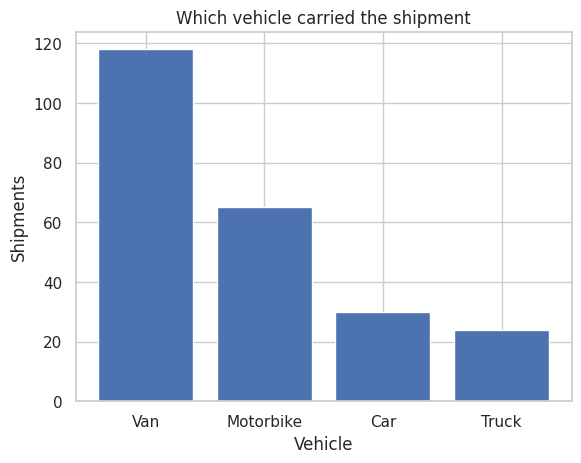

In [7]:
counts = df["vehicle"].value_counts()
fig, ax = plt.subplots()
ax.bar(counts.index, counts.values)
ax.set_xlabel("Vehicle")
ax.set_ylabel("Shipments")
ax.set_title("Which vehicle carried the shipment")
plt.show()


## 7. Pie chart

The same table, drawn as angles. A pie says "parts of a whole" and only stays readable with a few categories. Use the bar chart when the question is which category is larger.


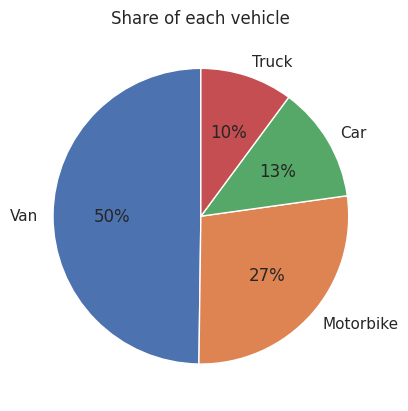

In [8]:
counts = df["vehicle"].value_counts()
fig, ax = plt.subplots()
ax.pie(counts.values, labels=counts.index, autopct="%1.0f%%", startangle=90)
ax.set_title("Share of each vehicle")
plt.show()


## 8. Grouped frequencies for a number

`minutes` has many distinct values, so group them into classes. Sturges' rule picks a starting number of classes: k = ceil(1 + log2 n). The cumulative proportion answers "what share finished below this class?". The fullest class is the modal class.


In [9]:
duration = df["minutes"].dropna()
k = math.ceil(1 + math.log2(len(duration)))
grouped = pd.cut(duration, bins=k).value_counts().sort_index().to_frame("f")
grouped["p"] = grouped["f"] / grouped["f"].sum()
grouped["cum_p"] = grouped["p"].cumsum()
print("classes", k)
grouped.round(3)


classes 9


,f,p,cum_p
minutes,,,
"(14.884, 27.889]",4,0.017,0.017
"(27.889, 40.778]",24,0.100,0.117
"(40.778, 53.667]",49,0.205,0.322
"(53.667, 66.556]",69,0.289,0.611
"(66.556, 79.444]",53,0.222,0.833
"(79.444, 92.333]",25,0.105,0.937
"(92.333, 105.222]",8,0.033,0.971
"(105.222, 118.111]",6,0.025,0.996
"(118.111, 131.0]",1,0.004,1.000


## 9. Center

`describe` bundles the usual numbers. The mean uses every value, so one extreme duration can pull it. The median is the middle of the sorted durations and stays put. For a continuous duration, quote the modal class from the grouped table rather than a single raw value.


In [10]:
print(df["minutes"].describe())
print("mean", round(duration.mean(), 2))
print("median", duration.median())
print("modal class", grouped["f"].idxmax())


count    239.000000
mean      62.569038
std       19.179012
min       15.000000
25%       49.500000
50%       62.000000
75%       74.000000
max      131.000000
Name: minutes, dtype: float64
mean 62.57
median 62.0
modal class (53.667, 66.556]


## 10. Spread

Variance is the average squared distance from the mean, in minutes squared. The standard deviation is its square root, back in minutes. The coefficient of variation is the standard deviation as a percent of the mean, so a count of failed attempts and a duration in minutes can be compared. Failed attempts vary much more, relative to their own mean, than durations do.


In [11]:
failed = df["failed_attempts"].dropna()
print("minutes sd", round(duration.std(), 2))
print("minutes variance", round(duration.var(), 2))
print("CV minutes", round(100 * duration.std() / duration.mean(), 1))
print("CV failed attempts", round(100 * failed.std() / failed.mean(), 1))


minutes sd 19.18
minutes variance 367.83
CV minutes 30.7
CV failed attempts 112.7


## 11. Quartiles and fences

Q1, the median, and Q3 cut the sorted durations into four equal parts. The IQR is Q3 minus Q1, the width of the middle half. Tukey fences sit 1.5 IQRs beyond Q1 and Q3. A duration outside a fence is a candidate to check, not an automatic error. pandas interpolates quartiles, so the cuts can differ slightly from a hand calculation.


In [12]:
q1 = duration.quantile(0.25)
q3 = duration.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Q1", q1, "Q3", q3, "IQR", iqr)
print("fences", lower, upper)
duration[(duration < lower) | (duration > upper)]


Q1 49.5 Q3 74.0 IQR 24.5
fences 12.75 110.75


11     113.0
85     112.0
159    131.0
182    112.0
Name: minutes, dtype: float64

## 12. Z-scores

A z-score is the distance from the mean in standard deviations. Flagging |z| > 2 is another outlier rule. It uses the mean, so a long tail of slow trips pulls the cut-offs. The fence rule does not. Say which rule you used.


In [13]:
z = (duration - duration.mean()) / duration.std()
duration[z.abs() > 2]


11     113.0
19     109.0
85     112.0
122    109.0
133    106.0
146    105.0
149     15.0
159    131.0
182    112.0
224     18.0
Name: minutes, dtype: float64

## 13. Shape

`skew` is the adjusted skewness from the slides. Above zero: a longer right tail, and the mean sits above the median. `kurt` is excess kurtosis: near zero means tails like a normal curve. With a few hundred rows, kurtosis is still rough. Read it next to the histogram, not instead of it.


In [14]:
print("minutes skew", round(df["minutes"].skew(), 2))
print("minutes kurtosis", round(df["minutes"].kurt(), 2))
print("failed attempts mean", round(failed.mean(), 2), "median", failed.median())
print("failed attempts skew", round(df["failed_attempts"].skew(), 2))
print("failed attempts kurtosis", round(df["failed_attempts"].kurt(), 2))


minutes skew 0.4
minutes kurtosis 0.39
failed attempts mean 1.35 median 1.0
failed attempts skew 1.02
failed attempts kurtosis 0.14


## 14. Histogram

The histogram is the grouped frequency table as a picture. Sturges gives the left-hand bin count. The right-hand chart uses many more bins. If a peak appears in only one of them, do not put that peak in the written summary.


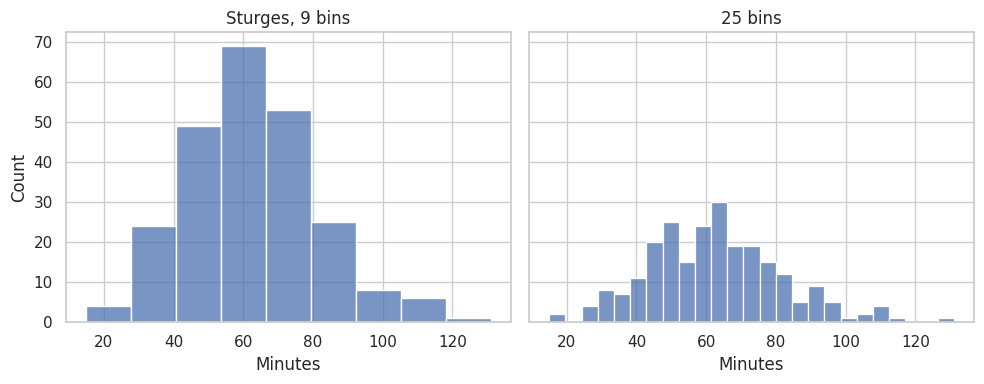

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
sns.histplot(duration, bins=k, ax=axes[0])
axes[0].set_title(f"Sturges, {k} bins")
axes[0].set_xlabel("Minutes")
sns.histplot(duration, bins=25, ax=axes[1])
axes[1].set_title("25 bins")
axes[1].set_xlabel("Minutes")
fig.tight_layout()
plt.show()


## 15. Density curve

A kernel density estimate places a small bump on every duration and adds the bumps. The bandwidth is the width of a bump, the same kind of choice as the bin width. The curve has area 1, so it can sit on top of a density histogram.


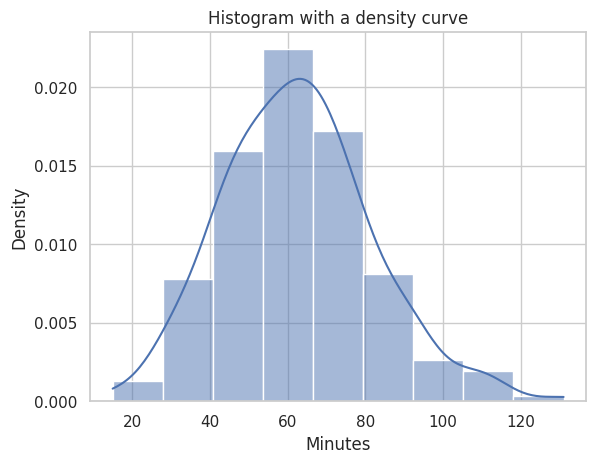

In [16]:
fig, ax = plt.subplots()
sns.histplot(duration, bins=k, stat="density", kde=True, ax=ax)
ax.set_xlabel("Minutes")
ax.set_title("Histogram with a density curve")
plt.show()


## 16. Box plot

The box runs from Q1 to Q3. The line inside is the median. Whiskers stop at the last durations inside the fences, and points beyond them are drawn alone. This is the picture to use when the next question is "do the depots differ?".


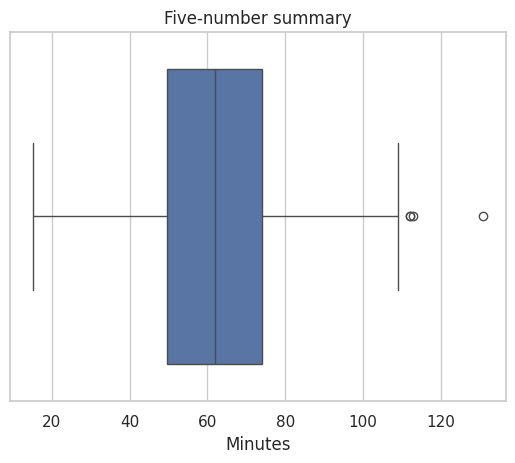

In [17]:
fig, ax = plt.subplots()
sns.boxplot(x=duration, ax=ax)
ax.set_xlabel("Minutes")
ax.set_title("Five-number summary")
plt.show()


## 17. Violin plot

A violin is that box plus a mirrored density curve. Two peaks, which a box hides, stay visible. The outline still depends on the bandwidth.


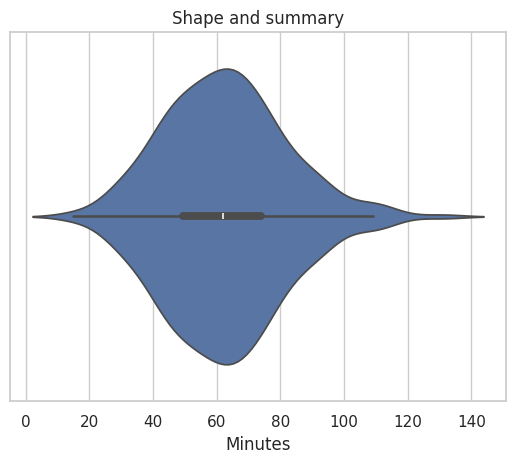

In [18]:
fig, ax = plt.subplots()
sns.violinplot(x=duration, ax=ax)
ax.set_xlabel("Minutes")
ax.set_title("Shape and summary")
plt.show()


## 18. Stem-and-leaf

Split each duration into a tens digit (the stem) and a units digit (the leaf). It is a histogram that still shows every value. Use it on a short list, such as a form you are checking by hand. Past a few dozen rows it becomes unreadable, and a histogram is the tool.


In [19]:
sample = sorted(int(value) for value in duration.sample(24, random_state=2))
buckets = {}
for value in sample:
    stem, leaf = divmod(value, 10)
    buckets.setdefault(stem, []).append(leaf)
for stem in range(min(buckets), max(buckets) + 1):
    leaves = " ".join(str(leaf) for leaf in buckets.get(stem, []))
    print(f"{stem} | {leaves}")
print("Key: 6 | 2 = 62 minutes")


3 | 9
4 | 0 3 8
5 | 0 1 1 6 7 8
6 | 8
7 | 0 2 5 6 9
8 | 2 3 4
9 | 0 5 6 8
10 | 
11 | 2
Key: 6 | 2 = 62 minutes


## 19. Two categories

A contingency table counts every pair of `service` and `on_time`. The margins are each column on its own. Row percentages answer the question a dispatch lead actually asks: among shipments in this service, what share was on time?


In [20]:
pd.crosstab(df["service"], df["on_time"], margins=True)


on_time,Late,On time,All
service,,,
Express,18,95,113
Standard,64,62,126
All,82,157,239


In [21]:
pd.crosstab(df["service"], df["on_time"], normalize="index").round(3)


on_time,Late,On time
service,,
Express,0.159,0.841
Standard,0.508,0.492


## 20. Could the gap be chance?

Expected counts are what the cells would hold if service and result were unrelated. Chi-square adds up how far the observed counts are from those. Cramér's V rescales that into a number from 0 to 1: about 0.1 is weak, 0.3 moderate, 0.5 strong. A small p-value means the gap is large for this sample size. It does not mean the service caused the on-time result. Every expected count should be at least 5.


In [22]:
counts = pd.crosstab(df["service"], df["on_time"])
chi2, p_value, dof, expected = stats.chi2_contingency(counts)
n = counts.to_numpy().sum()
v = (chi2 / (n * (min(counts.shape) - 1))) ** 0.5
print("chi-square", round(chi2, 2))
print("df", dof)
print("p", "< 0.0001" if p_value < 0.0001 else round(p_value, 4))
print("Cramers V", round(v, 3))
pd.DataFrame(expected, index=counts.index, columns=counts.columns).round(1)


chi-square 30.6
df 1
p < 0.0001
Cramers V 0.358


on_time,Late,On time
service,,
Express,38.8,74.2
Standard,43.2,82.8


## 21. Covariance

Covariance is the average product of the two deviations from their means. A positive sign means the columns move together. The number still carries units, kilometres times minutes, so its size is not a strength. Correlation removes the units.


In [23]:
df[["distance_km", "minutes", "failed_attempts"]].cov().round(2)


,distance_km,minutes,failed_attempts
distance_km,10.58,30.69,-0.08
minutes,30.69,367.83,17.91
failed_attempts,-0.08,17.91,2.33


## 22. Correlation matrix

Pearson r divides the covariance by the two standard deviations. It is always between -1 and 1, and it measures a straight-line association. The diagonal is 1. |r| below 0.3 is weak, 0.3 to 0.7 moderate, above 0.7 strong. A strong pair can be redundant: stops and distance are partly the same fact twice.


In [24]:
df[["distance_km", "failed_attempts", "stops", "minutes"]].corr().round(3)


,distance_km,failed_attempts,stops,minutes
distance_km,1.000,-0.016,0.757,0.493
failed_attempts,-0.016,1.000,-0.002,0.611
stops,0.757,-0.002,1.000,0.358
minutes,0.493,0.611,0.358,1.000


## 23. Pearson and Spearman

Spearman ρ is Pearson correlation on the ranks. It follows any steady rise or fall, and an odd point moves it less. If the two numbers agree, the cloud is close to a straight line. Look at the scatter before you quote either one.


In [25]:
pair = df[["distance_km", "minutes"]].dropna()
print("Pearson", round(pair.corr().iloc[0, 1], 3))
print("Spearman", round(pair.corr(method="spearman").iloc[0, 1], 3))


Pearson 0.493
Spearman 0.459


## 24. Scatter plot and a straight line

One point per shipment. The line is the least-squares line: slope = covariance term / variance of x. The slope is the average change in minutes per extra kilometre in this table. R² = r² is the share of duration variation that sits on that line. Neither number is a reason to tell dispatch that distance caused the result.


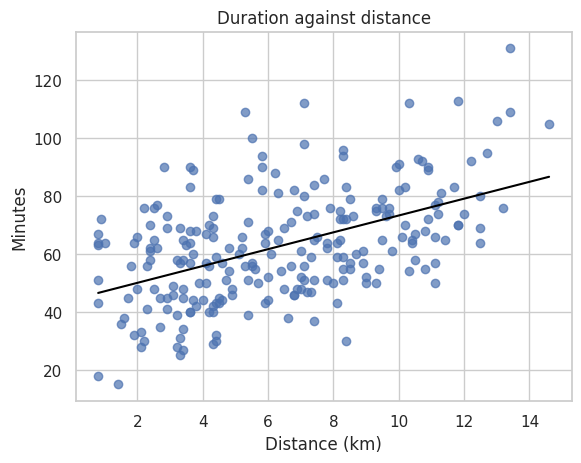

minutes = 44.3 + 2.9 * km
r 0.493 R2 0.243


In [26]:
slope, intercept, r, p_value, se = stats.linregress(pair["distance_km"], pair["minutes"])
fig, ax = plt.subplots()
ax.scatter(pair["distance_km"], pair["minutes"], alpha=0.7)
x = np.linspace(pair["distance_km"].min(), pair["distance_km"].max(), 50)
ax.plot(x, intercept + slope * x, color="black")
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Minutes")
ax.set_title("Duration against distance")
plt.show()
print(f"minutes = {intercept:.1f} + {slope:.1f} * km")
print("r", round(r, 3), "R2", round(r ** 2, 3))


## 25. A third column as size

A bubble chart keeps x and y and encodes another number as area. Scale area, not radius, or a large value looks enormous. Size is for a rough magnitude. If failed attempts must be read precisely, use colour or a chart of their own. seaborn's `sizes` scales area.


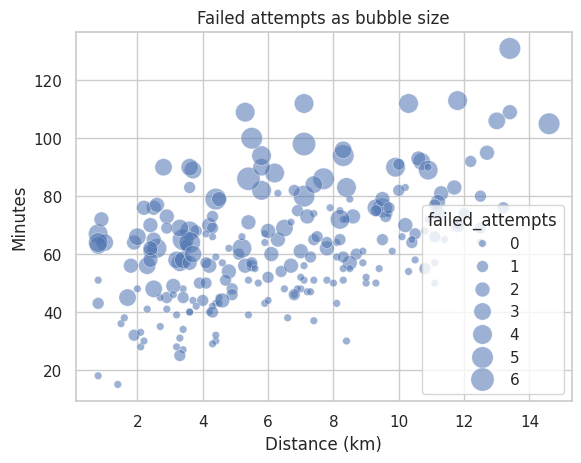

In [27]:
plot_df = df.dropna(subset=["distance_km", "minutes", "failed_attempts"])
fig, ax = plt.subplots()
sns.scatterplot(
    data=plot_df,
    x="distance_km",
    y="minutes",
    size="failed_attempts",
    sizes=(30, 280),
    alpha=0.55,
    ax=ax,
)
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Minutes")
ax.set_title("Failed attempts as bubble size")
plt.show()


## 26. The same numbers, per depot

Split by depot, then compute count, mean, median, and standard deviation in each group. Two groups can share a mean and still differ in spread, so the mean alone is not the comparison. When you put the group means back together, weight each one by its count. Industrial is smaller than the others and slower. Treating the four means as equal would make the day look slower than it was.


In [28]:
summary = df.groupby("depot")["minutes"].agg(["count", "mean", "median", "std"])
weighted = (summary["count"] * summary["mean"]).sum() / summary["count"].sum()
print("weighted mean", round(weighted, 2))
print("unweighted mean of means", round(summary["mean"].mean(), 2))
summary.round(2)


weighted mean 62.57
unweighted mean of means 64.39


,count,mean,median,std
depot,,,,
Airport,63,61.10,58.0,17.50
Central,68,52.68,54.5,16.80
Harbor,66,61.85,63.0,15.74
Industrial,42,81.93,78.0,16.35


## 27. Boxes side by side

One box per depot, on the same scale, ordered by the median. Compare the lines (center), the box lengths (spread), and the overlap. Little overlap means the groups really sit apart in this table. Small groups make the quartiles jumpy; the raw count from the last cell belongs next to this picture.


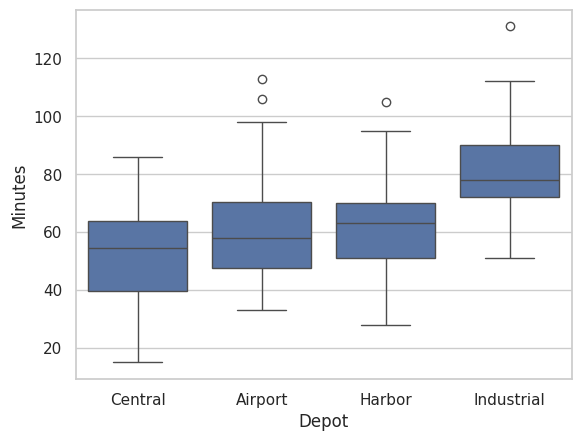

In [29]:
order = summary["median"].sort_values().index
fig, ax = plt.subplots()
sns.boxplot(data=df, x="depot", y="minutes", order=order, ax=ax)
ax.set_xlabel("Depot")
ax.set_ylabel("Minutes")
plt.show()


## 28. The same chart in panels

A facet repeats one plot per group and keeps the axes identical, so the eye can compare panels instead of untangling several colours. A shared axis is the whole point: if each panel chose its own scale, a tall bar would not mean the same thing.


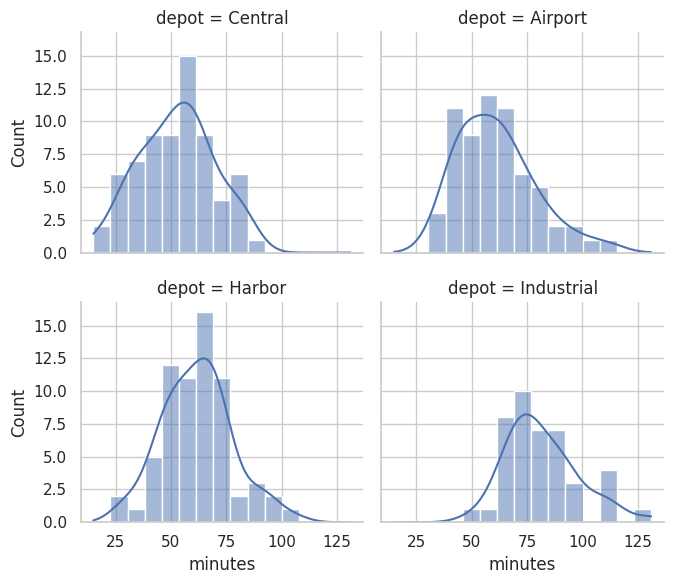

In [30]:
sns.displot(
    data=df,
    x="minutes",
    col="depot",
    col_order=list(order),
    col_wrap=2,
    kde=True,
    height=3,
    aspect=1.15,
)
plt.show()


## 29. Heatmap

Colour the correlation matrix. A diverging palette puts a neutral colour at zero, and the scale is fixed from -1 to 1 so blue means the same thing every time. The numbers stay in the cells. Any strong pair still needs the scatter plot from earlier: colour is a scan, not the evidence.


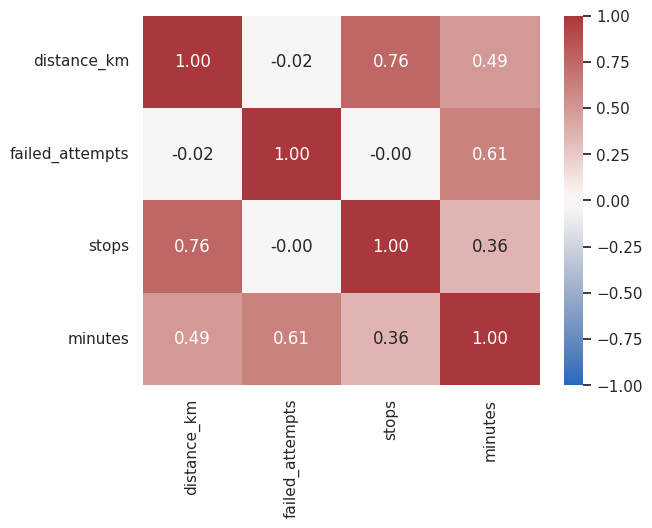

In [31]:
columns = ["distance_km", "failed_attempts", "stops", "minutes"]
fig, ax = plt.subplots()
sns.heatmap(
    df[columns].corr(),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0,
    cmap="vlag",
    ax=ax,
)
plt.show()


## 30. Parallel coordinates

Each column is a vertical axis, scaled from 0 to 1 so kilometres and minutes can share a line. Each line is one shipment. Lines that climb together are a positive link. Lines that cross are a negative link. Axis order decides which pair you can see. Two hundred lines would hide the pattern, so this is a sample of 30.


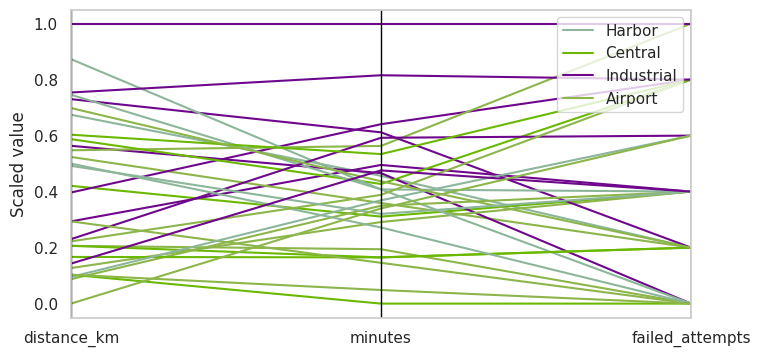

In [32]:
columns = ["distance_km", "minutes", "failed_attempts"]
sample = df[["depot", *columns]].dropna().sample(30, random_state=1).copy()
for column in columns:
    low = sample[column].min()
    high = sample[column].max()
    sample[column] = (sample[column] - low) / (high - low)
fig, ax = plt.subplots(figsize=(8, 4))
pd.plotting.parallel_coordinates(sample, "depot", ax=ax)
ax.set_ylabel("Scaled value")
plt.show()


## 31. The same summary as a function

Pass a numeric column. The function returns the center, the spread, and the skew. Call it on a new column by changing the argument, the same way week 1 called `scrape` and week 2 called `draw`.


In [33]:
def summarize(series):
    series = series.dropna()
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    return pd.Series({
        "n": series.size,
        "mean": series.mean(),
        "median": series.median(),
        "std": series.std(),
        "iqr": q3 - q1,
        "skew": series.skew(),
    })


In [34]:
pd.DataFrame({
    "minutes": summarize(df["minutes"]),
    "failed_attempts": summarize(df["failed_attempts"]),
}).round(2)


,minutes,failed_attempts
n,239.00,240.00
mean,62.57,1.35
median,62.00,1.00
std,19.18,1.53
iqr,24.50,2.00
skew,0.40,1.02


## 32. The page for the meeting

This is what you would take into the room: how many shipments, the on-time rate in each service, the median duration in each depot, and the straight-line link between distance and duration. It raises the questions. It does not choose a policy, and it does not claim a cause. Those need a design this table does not contain.


In [35]:
print("shipments", len(df))
print("missing durations", int(df["minutes"].isna().sum()))
print(pd.crosstab(df["service"], df["on_time"], normalize="index").round(2))
print("Pearson r, distance and minutes", round(pair["distance_km"].corr(pair["minutes"]), 2))
df.groupby("depot")["minutes"].median().sort_values()


shipments 240
missing durations 1
on_time   Late  On time
service                
Express   0.16     0.84
Standard  0.51     0.49
Pearson r, distance and minutes 0.49


depot
Central       54.5
Airport       58.0
Harbor        63.0
Industrial    78.0
Name: minutes, dtype: float64